Credit Card Fraud Detection & Cost-Optimized Decision Threshold

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, precision_recall_curve, average_precision_score,classification_report,confusion_matrix,f1_score,precision_score,recall_score


In [2]:
# Load data
df = pd.read_csv("../data/raw/indian_transactions.csv")

In [3]:
df

,trans_datetime,trans_date,trans_time,cc_num,cardholder_name,gender,dob,age,job,state,merchant,category,payment_method,upi_id,amt_inr,trans_num,is_fraud,fraud_reason
0,2023-01-01 00:04:17,2023-01-01,00:04:17,4263775255231016,Aayush Pant,M,1963-12-06,62,HR Manager,Karnataka,Meesho,shopping_net,Debit Card,NaN,1718.03,F9B3BD3C357043C6B48ACC9D,0,NaN
1,2023-01-01 00:05:11,2023-01-01,00:05:11,4104527616086512,Chameli Gupta,F,1980-05-10,46,Software Engineer,Karnataka,Reliance Retail,shopping_pos,Net Banking,NaN,1004.24,B06A1987623940D19FEEEFD0,0,NaN
2,2023-01-01 00:08:21,2023-01-01,00:08:21,4050625600458037,Suhani Rao,F,1987-09-02,38,HR Manager,Maharashtra,Vijay Sales,misc_pos,UPI,logangar@okaxis,8345.16,3EDC3591F0DE42C9AF544982,0,NaN
3,2023-01-01 00:13:36,2023-01-01,00:13:36,4048717838376687,Andrew Dara,M,1999-08-13,26,Data Analyst,Uttar Pradesh,PetSutra,kids_pets,UPI,mukhopad@freecharge,1250.43,D35289961B7841EB9FBA1A38,0,NaN
4,2023-01-01 00:16:58,2023-01-01,00:16:58,4587474764756477,Guneet Kari,M,1988-11-24,37,Software Engineer,West Bengal,Zepto,grocery_net,Debit Card,NaN,1299.76,C5BA9670B9D14DB4968A7933,0,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
499995,2024-12-30 23:36:20,2024-12-30,23:36:20,4585457877603323,Aryan Sarin,M,2001-06-22,25,Product Manager,Telangana,Uber India,gas_transport,Credit Card,NaN,2746.07,6A23CC92B74B41DD972ECD00,0,NaN
499996,2024-12-30 23:43:05,2024-12-30,23:43:05,4352066381026815,Aayush Bhasin,M,1977-10-28,48,Teacher,Maharashtra,Myntra,shopping_net,Credit Card,NaN,3775.91,D4B78B619F294DF0BFE9B245,0,NaN
499997,2024-12-30 23:46:27,2024-12-30,23:46:27,4674432755134424,Siya Murthy,F,2004-08-20,21,Government Employee,Delhi,Milkbasket,grocery_net,UPI,wsrivast@freecharge,1558.17,44C7AF29ABF94F67B3E8296D,0,NaN
499998,2024-12-30 23:48:03,2024-12-30,23:48:03,4177428607458724,Krisha Yohannan,F,1997-03-04,29,Business Owner,Gujarat,Nilgiris,grocery_pos,UPI,kdesai@okicici,1139.90,A04674E9B48044D8A8D43086,0,NaN


In [4]:
print(f"Dataset shape: {df.shape}")

Dataset shape: (500000, 18)


In [5]:
print(f"Data types: {df.dtypes}")

Data types: trans_datetime      object
trans_date          object
trans_time          object
cc_num               int64
cardholder_name     object
gender              object
dob                 object
age                  int64
job                 object
state               object
merchant            object
category            object
payment_method      object
upi_id              object
amt_inr            float64
trans_num           object
is_fraud             int64
fraud_reason        object
dtype: object


In [6]:
df.columns

Index(['trans_datetime', 'trans_date', 'trans_time', 'cc_num',
       'cardholder_name', 'gender', 'dob', 'age', 'job', 'state', 'merchant',
       'category', 'payment_method', 'upi_id', 'amt_inr', 'trans_num',
       'is_fraud', 'fraud_reason'],
      dtype='object')

In [7]:
print(f"Null values: {df.isnull().sum()}")

Null values: trans_datetime          0
trans_date              0
trans_time              0
cc_num                  0
cardholder_name         0
gender                  0
dob                     0
age                     0
job                     0
state                   0
merchant                0
category                0
payment_method          0
upi_id             299412
amt_inr                 0
trans_num               0
is_fraud                0
fraud_reason       490074
dtype: int64


In [8]:
print(f"Null values: {df.isna().sum()}")

Null values: trans_datetime          0
trans_date              0
trans_time              0
cc_num                  0
cardholder_name         0
gender                  0
dob                     0
age                     0
job                     0
state                   0
merchant                0
category                0
payment_method          0
upi_id             299412
amt_inr                 0
trans_num               0
is_fraud                0
fraud_reason       490074
dtype: int64


In [9]:
print(f"Duplicate rows: {df.duplicated().sum()}")

Duplicate rows: 0


In [10]:
# Target Distribution
fraud_counts = df['is_fraud'].value_counts()
fraud_pct = df['is_fraud'].value_counts(normalize=True)*100
print(fraud_counts)
print(fraud_pct)

is_fraud
0    490074
1      9926
Name: count, dtype: int64
is_fraud
0    98.0148
1     1.9852
Name: proportion, dtype: float64


In [11]:
print(f"Legitimate (0): {fraud_counts[0]:,} ({fraud_pct[0]:.2f}%)")
print(f"Fradulent (1): {fraud_counts[1]:,} ({fraud_pct[1]:.2f}%)")
print(f"Class Imbalance: {fraud_counts[0]//fraud_counts[1]}:1")

Legitimate (0): 490,074 (98.01%)
Fradulent (1): 9,926 (1.99%)
Class Imbalance: 49:1


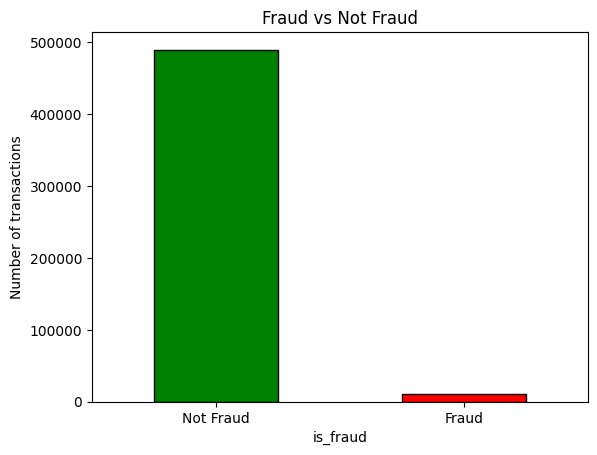

In [12]:
# Class Distribution (plots)
# Bar Chart
df['is_fraud'].value_counts().plot(kind='bar',color=['green','red'],edgecolor='black')
plt.title("Fraud vs Not Fraud")
plt.xticks([0,1],['Not Fraud','Fraud'],rotation=0)
plt.ylabel('Number of transactions')
plt.show()


Exploratory Data Analysis (EDA)

In [13]:
# Separate amounts for fraud and not fraud
fraud_amt = df[df['is_fraud'] == 1]['amt_inr']
legit_amt = df[df['is_fraud'] == 0]['amt_inr']
print(fraud_amt)
print(legit_amt)

31         8055.70
39        34783.31
64        18569.05
109       88722.26
116       14609.78
            ...   
499402    38526.70
499457      608.39
499477     8755.41
499909    13327.42
499989     4261.32
Name: amt_inr, Length: 9926, dtype: float64
0         1718.03
1         1004.24
2         8345.16
3         1250.43
4         1299.76
           ...   
499995    2746.07
499996    3775.91
499997    1558.17
499998    1139.90
499999      95.32
Name: amt_inr, Length: 490074, dtype: float64


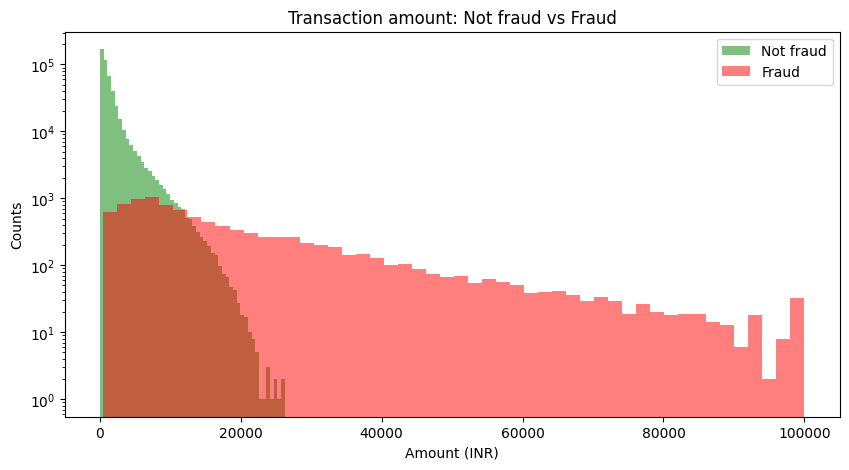

In [14]:
# Plot both on the same chart
plt.figure(figsize=(10,5))
plt.hist(legit_amt,bins=50,alpha = 0.5,label='Not fraud',color='green')
plt.hist(fraud_amt,bins=50,alpha=0.5,label='Fraud',color='red')
plt.title("Transaction amount: Not fraud vs Fraud")
plt.xlabel("Amount (INR)")
plt.ylabel("Counts")
plt.legend()
plt.yscale('log') #so that we can see the small fraud bars
plt.show()

In [15]:
# For each category, calculating how many are fraud and what % are fraud
category_stats = df.groupby('category')['is_fraud'].agg(['sum','mean'])
category_stats.columns = ['fraud_count','fraud_rate']
category_stats = category_stats.sort_values('fraud_count',ascending=False)
print(category_stats.head(10))

               fraud_count  fraud_rate
category                              
shopping_net          1946    0.030578
travel                1701    0.046488
food_dining           1267    0.015496
shopping_pos          1029    0.015128
grocery_pos            764    0.013985
grocery_net            537    0.014792
misc_net               494    0.027135
gas_transport          466    0.014598
entertainment          457    0.014435
misc_pos               368    0.020086


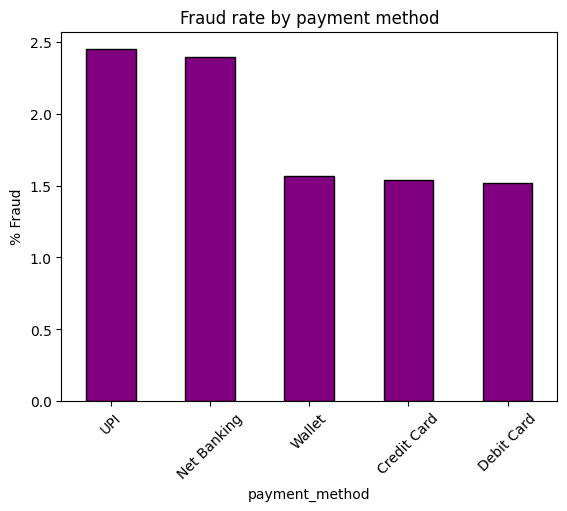

In [16]:
#  What % of each payment method is fraud
payment_method_fraud = df.groupby('payment_method')['is_fraud'].mean()*100
payment_method_fraud.sort_values(ascending=False).plot(kind='bar',color='purple',edgecolor='black')
plt.title('Fraud rate by payment method')
plt.ylabel("% Fraud")
plt.xticks(rotation = 45)
plt.show()

Preprocessing

In [17]:
# converting date-time col to proper datetime col
df['trans_datetime'] = pd.to_datetime(df['trans_datetime'])

In [18]:
df['hour'] = df['trans_datetime'].dt.hour
df['day_of_week'] = df['trans_datetime'].dt.dayofweek

# Dropping columns that dont help predict fraud
drop_cols = ['trans_datetime','trans_date','trans_time',
             'cc_num','cardholder_name','dob','upi_id',
             'trans_num','fraud_reason']

df_clean = df.drop(columns = drop_cols)

In [19]:
# Converting text cols into number using one-hot encoding
text_cols = ['gender','job','state','merchant','category','payment_method']
df_clean = pd.get_dummies(df_clean, columns=text_cols,drop_first=True)
print("Final shape",df_clean.shape)

Final shape (500000, 187)


In [20]:
# split into train and test
X = df_clean.drop('is_fraud',axis=1)
y = df_clean['is_fraud']

In [ ]:
print("Missing target values:", df_clean["is_fraud"].isna().sum())
print(df_clean["is_fraud"].value_counts(dropna=False))

Missing target values: 0
is_fraud
0    490074
1      9926
Name: count, dtype: int64


In [22]:
df_clean = df_clean.dropna(subset=["is_fraud"]).copy()

X = df_clean.drop(columns=["is_fraud"])
y = df_clean["is_fraud"].astype("int64")

In [23]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state = 1,stratify=y)
print("Training rows :",len(X_train))
print("Testing rows :",len(X_test))

Training rows : 400000
Testing rows : 100000


In [24]:
from sklearn.preprocessing import StandardScaler

In [25]:
sc = StandardScaler()
xtrain_scaled = pd.DataFrame(sc.fit_transform(X_train))
xtest_scaled = pd.DataFrame(sc.fit_transform(X_test))


Model Training

In [26]:
lr = LogisticRegression(class_weight='balanced',max_iter=1000,random_state=1)
lr.fit(xtrain_scaled,y_train)
lr_proba = lr.predict_proba(xtest_scaled)[:,1]
lr_preds = (lr_proba >= 0.5).astype(int)
print("Logistic Regression Results:")
print(classification_report(y_test,lr_preds))
print(confusion_matrix(y_test,lr_preds))

Logistic Regression Results:
              precision    recall  f1-score   support

           0       1.00      0.98      0.99     98015
           1       0.47      0.89      0.62      1985

    accuracy                           0.98    100000
   macro avg       0.73      0.94      0.80    100000
weighted avg       0.99      0.98      0.98    100000

[[96007  2008]
 [  210  1775]]


In [27]:
rf = RandomForestClassifier(n_estimators=200,class_weight='balanced',random_state=1)
rf.fit(X_train,y_train)
rf_proba = rf.predict_proba(X_test)[:,1]
rf_preds = (rf_proba >= 0.5).astype(int)
print("RandomForest Results:")
print(classification_report(y_test,rf_preds))
print(confusion_matrix(y_test,rf_preds))

RandomForest Results:
              precision    recall  f1-score   support

           0       0.99      1.00      1.00     98015
           1       0.99      0.75      0.85      1985

    accuracy                           0.99    100000
   macro avg       0.99      0.87      0.93    100000
weighted avg       0.99      0.99      0.99    100000

[[98005    10]
 [  498  1487]]


In [28]:
print(df.columns.tolist())
print("is_fraud" in df.columns)

['trans_datetime', 'trans_date', 'trans_time', 'cc_num', 'cardholder_name', 'gender', 'dob', 'age', 'job', 'state', 'merchant', 'category', 'payment_method', 'upi_id', 'amt_inr', 'trans_num', 'is_fraud', 'fraud_reason', 'hour', 'day_of_week']
True


In [29]:
fraud_counts = y.value_counts()
fraud_counts

is_fraud
0    490074
1      9926
Name: count, dtype: int64

In [30]:
from xgboost import XGBClassifier

In [31]:
# Calculate ratio for class balancing
neg_count = (y_train == 0).sum()
pos_count = (y_train == 1).sum()

In [32]:
xgb = XGBClassifier(
    n_estimators = 300,
    max_depth = 6,
    learning_rate = 0.1,
    scale_pos_weight = neg_count/pos_count,
    random_state = 1
)

xgb.fit(X_train,y_train,verbose = False)
xgb_proba = xgb.predict_proba(X_test)[:,1]
xgb_preds = (xgb_proba >= 0.5).astype(int)


print("XGBoost Results:")
print(classification_report(y_test,xgb_preds))
print(confusion_matrix(y_test,xgb_preds))

XGBoost Results:
              precision    recall  f1-score   support

           0       1.00      0.99      0.99     98015
           1       0.60      0.92      0.73      1985

    accuracy                           0.99    100000
   macro avg       0.80      0.95      0.86    100000
weighted avg       0.99      0.99      0.99    100000

[[96821  1194]
 [  157  1828]]


In [33]:
models = {
    "Logistic Regression": lr_preds,
    "XGBoost": xgb_preds,
    "Random Forest": rf_preds,
}

results = {}

for name, preds in models.items():
    results[name] = {
        "precision": precision_score(y_test, preds),
        "recall": recall_score(y_test, preds),
        "f1_score": f1_score(y_test, preds),
        "confusion_matrix": confusion_matrix(y_test, preds)
    }

    print(f"\n{name}")
    print(classification_report(y_test, preds))
    print(confusion_matrix(y_test, preds))

best_model = max(results, key=lambda k: results[k]["f1_score"])

print("\nBest model:")
print(best_model)
print(results[best_model])


Logistic Regression
              precision    recall  f1-score   support

           0       1.00      0.98      0.99     98015
           1       0.47      0.89      0.62      1985

    accuracy                           0.98    100000
   macro avg       0.73      0.94      0.80    100000
weighted avg       0.99      0.98      0.98    100000

[[96007  2008]
 [  210  1775]]

XGBoost
              precision    recall  f1-score   support

           0       1.00      0.99      0.99     98015
           1       0.60      0.92      0.73      1985

    accuracy                           0.99    100000
   macro avg       0.80      0.95      0.86    100000
weighted avg       0.99      0.99      0.99    100000

[[96821  1194]
 [  157  1828]]

Random Forest
              precision    recall  f1-score   support

           0       0.99      1.00      1.00     98015
           1       0.99      0.75      0.85      1985

    accuracy                           0.99    100000
   macro avg       0.

SHAP Explainability

In [34]:
import shap

In [ ]:
# 1. Sample first (1000 rows)
X_test_sample = X_test.sample(1000, random_state=1)

# 2. Compute SHAP on sample
explainer = shap.TreeExplainer(rf)
shap_values = explainer.shap_values(X_test_sample)

# 3. Feature importance from sample
feature_importance = pd.DataFrame({
    'feature': X_test_sample.columns,
    'importance': np.abs(shap_values).mean(axis=0)
}).sort_values('importance', ascending=False)

print(feature_importance.head(20))  # See ranked list

# 4. Plot
shap.summary_plot(shap_values, X_test_sample, max_display=15, show=False)
plt.title("Random Forest - What Features Drive Fraud?")
plt.tight_layout()
plt.show()

Cost-sensitive threshold optimization

In [ ]:
# Indian banking cost from (RBI Data)
C_FP = 500  # Cost of false alarm
C_FN = 10000 # Cost of missing fraud

print("False alarm cost Rs: ",C_FP)
print("Missing fraud cost Rs: ",C_FN)
print("Ratio: Missing fraud is", C_FN // C_FP,"x worse than false alarm")

False alarm cost Rs:  500
Missing fraud cost Rs:  10000
Ratio: Missing fraud is 20 x worse than false alarm


This is the whole point of the project. Missing a fraud transaction costs Rs. 10,000 (chargeback + loss), but a false alarm only costs Rs. 500 (investigation). So we should err on the side of catching more fraud even if it means more false alarms.

In [ ]:
# Find the best threshold from 0.01 to 0.99
best_threshold = 0.5
best_cost = float('inf')
all_threshold = []
all_cost = []

for threshold in np.arange(0.01,1.00,0.01):
    preds = (rf_proba >= threshold).astype(int)
    tn,fp,fn,tp = confusion_matrix(y_test,preds).ravel()
    cost = (C_FN * fn) + (C_FP * fp)

    all_threshold.append(threshold)
    all_cost.append(cost)

    if cost < best_cost:
        best_cost = cost
        best_threshold = threshold

print("Best threshold:", round(best_threshold),2)
print("Cost at best threshold: Rs. ", round(best_cost))


We test every possible threshold (0.01, 0.02, ... 0.99) and pick the one that costs the least money. This is NOT about accuracy — it's about minimizing real financial loss.

In [ ]:
# Plot Cost vs threshold
plt.figure(figsize=(10,5))
plt.plot(all_threshold,all_cost,'b-',linewidth=2)
plt.axvline(x=best_threshold,color='green',linestyle='--',label=f'Best threshold = {round(best_threshold,2)}')
plt.title("Total cost vs Decision threshold")
plt.xlabel("Threshold")
plt.ylabel("Total cost (Rs.)")
plt.legend()
plt.show()


This chart is the "money chart." It shows a U-shaped curve where the bottom is the cheapest threshold. The green line shows the optimal threshold; the red line shows the default (0.50) you can see the optimal is usually lower.

In [ ]:
# Compare three strategies

# Strategy 1: Default threshold (0.5)
preds_default = (rf_proba >= 0.5).astype(int)

# Strategy 2: Best threshold ( what we just found)
preds_optimal = (rf_proba >= best_threshold).astype(int)

# Strategy 3: Threshold that maximizes F1 Score
f1_scores = [f1_score(y_test,(rf_proba >= t).astype(int))
             for t in np.arange(0.01,1.00,0.01)]
f1_threshold = np.arange(0.01,1.00,0.01)[np.argmax(f1_score)]
preds_f1 = (rf_proba >= f1_threshold).astype(int)

# Comparing all three
strategies = {
    "Default (0.50)":preds_default,
    f"F1-optimized ({round(f1_threshold,2)})": preds_f1,
    f"Cost-optimized ({round(best_threshold,2)})":preds_optimal
}

for name,preds in strategies.items():
    tn,fp,fn,tp = confusion_matrix(y_test,preds).ravel()
    cost = (C_FN * fn) + (C_FP * fp)
    print(f"\n{name}")
    print(f"Missed Fraud (FN): {fn} | False Alarms (FP): {fp}")
    print(f"Total cost: Rs. {cost:,.0f}")
    

Shows three different strategies side by side. The cost-optimized strategy catches more fraud (lower FN) even though it has more false alarms (higher FP) because missing fraud is 20x more expensive.

In [ ]:
# How much money did we save ?
tn_d,fn_d,fp_d,tp_d = confusion_matrix(y_test,preds_default).ravel()
tn_o,fn_o,fp_o,tp_o = confusion_matrix(y_test,preds_optimal).ravel()

cost_default = (C_FN * fn_d) + (C_FP * fp_d)
cost_optimal = (C_FN * fn_o) + (C_FP * fp_o)
savings = cost_default-cost_optimal

print(f"Default threshold cost: Rs. {cost_default:,.0f}")
print(f"Optimized threshold cost: Rs. {cost_optimal:,.0f}")
print(f"Savings on test set: Rs. {savings:,.0f}")
print(f"Savings per 10,000 transactions: Rs. {savings / len(y_test) * 10000:,.0f}")

Translates everything into rupees. "By switching from default to optimized threshold, we saved Rs. X on the test set."

In [ ]:
# Annual Projection
# a mid size indian bank processes ~5 millon transactions/month
annual_transactions = 600_000_00
annual_savings = (savings/len(y_test) * annual_transactions)
print(f"Annual savings projection: Rs. {annual_savings/1e7:,.2f} crore")